In [1]:
# Exercice 5 : Réseau de neurones sur le dataset Titanic

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import networkx as nx
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

# Fixer la graine aléatoire pour la reproductibilité
tf.keras.utils.set_random_seed(42)

I0000 00:00:1791836855.738098  126635 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791836855.788370  126635 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791836856.889261  126635 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
# 1. Chargement du dataset Titanic via Seaborn
titanic = sns.load_dataset("titanic")
print("Aperçu des données brutes :")
titanic.head()

Aperçu des données brutes :


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [5]:
titanic.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [6]:
# 1. Sélection des colonnes (features) pertinentes pour notre modèle
# On choisit de garder les informations socio-économiques, démographiques et tarifaires du passager
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']

# X représente les données d'entrée (les caractéristiques des passagers)
X = titanic[features]

# y représente la cible (target) que le modèle doit apprendre à prédire : 
# 1 si le passager a survécu, 0 s'il n'a pas survécu
# On utilise .values pour convertir la colonne pandas en tableau numpy brut
y = titanic['survived'].values

In [7]:
# 2. Séparer les données en Train (apprentissage) et Test (évaluation)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,       # 20% des données sont réservées pour le test final, 80% pour l'entraînement
    stratify=y,          # Garantit que la proportion de survivants/décédés est la même dans train et test
    random_state=42      # Graine aléatoire pour assurer la reproductibilité des mélanges
)

In [8]:
# 3. Gérer les valeurs manquantes (imputation)
# Règle d'or : On calcule les valeurs de remplacement (médiane, mode) 
# UNIQUEMENT sur le jeu d'entraînement pour éviter le data leakage.

age_median = X_train['age'].median()       # On calcule l'âge médian du train
embarked_mode = X_train['embarked'].mode()[0] # On trouve le port d'embarquement le plus fréquent (mode) du train

# On remplit les valeurs manquantes (NaN) de l'âge par la médiane, et celles de l'embarquement par le mode
# Cette même règle (calculée sur le train) est appliquée à la fois sur X_train et X_test
X_train = X_train.fillna({'age': age_median, 'embarked': embarked_mode})
X_test = X_test.fillna({'age': age_median, 'embarked': embarked_mode})

# Vérification : on s'assure qu'il ne reste plus aucune valeur manquante (0 et 0)
print("Valeurs manquantes restantes :", X_train.isna().sum().sum(), X_test.isna().sum().sum())

Valeurs manquantes restantes : 0 0


In [9]:
# 4. Encoder les variables catégorielles (One-Hot Encoding)
# On liste les colonnes contenant du texte ou des catégories discrètes
cat = ['sex', 'embarked', 'pclass']

# pd.get_dummies transforme chaque catégorie en une nouvelle colonne binaire (0 ou 1)
# drop_first=True permet de supprimer la première colonne de chaque groupe pour éviter la colinéarité (redondance statistique)
X_train = pd.get_dummies(X_train, columns=cat, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat, drop_first=True)

# Étape cruciale : on s'assure que X_test possède exactement les mêmes colonnes que X_train
# S'il manque une catégorie dans le test, reindex la rajoute et met la valeur 0 par défaut
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Affichage des 5 premières lignes transformées pour vérification
X_train.head()

,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,pclass_2,pclass_3
692,28.5,0,0,56.4958,True,False,True,False,True
481,28.5,0,0,0.0000,True,False,True,True,False
527,28.5,0,0,221.7792,True,False,True,False,False
855,18.0,0,1,9.3500,False,False,True,False,True
801,31.0,1,1,26.2500,False,False,True,True,False


In [10]:
# 5. Normaliser les features numériques (Standardisation)
# On cible uniquement les colonnes continues qui ont de grands écarts de valeurs (l'âge et le prix du billet)
num = ['age', 'fare']

scaler = StandardScaler()

# fit_transform calcule la moyenne et l'écart-type UNIQUEMENT sur le train et applique la transformation
X_train[num] = scaler.fit_transform(X_train[num])  # fit sur le train uniquement

# transform applique STRICTEMENT les mêmes paramètres (moyenne/écart-type du train) sur le test
# Cela évite toute fuite de données (data leakage)
X_test[num] = scaler.transform(X_test[num])

# Affichage des premières lignes pour vérifier que l'âge et le fare sont bien centrés-réduits
X_train.head()

,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,pclass_2,pclass_3
692,-0.081135,0,0,0.513812,True,False,True,False,True
481,-0.081135,0,0,-0.662563,True,False,True,True,False
527,-0.081135,0,0,3.955399,True,False,True,False,False
855,-0.887827,0,1,-0.467874,False,False,True,False,True
801,0.110934,1,1,-0.115977,False,False,True,True,False


In [11]:
# 6. Conversion en numpy array (format natif attendu par TensorFlow / Keras)
# On sauvegarde d'abord la liste des noms de colonnes (utile si on veut faire de l'interprétabilité plus tard)
feature_names = list(X_train.columns)

# On transforme les DataFrames Pandas en tableaux de nombres bruts (numpy arrays) 
# et on force le type en 'float32' (standard de précision pour les calculs sur GPU/CPU en Deep Learning)
X_train = X_train.values.astype('float32')
X_test = X_test.values.astype('float32')

In [12]:
# 7. Vérifier les dimensions (shapes) des tenseurs avant de construire le modèle
# Permet de s'assurer que le nombre de lignes et de colonnes correspond bien à nos attentes
print("Shape X_train:", X_train.shape)  # Ex: (712 lignes, nombre de features encodées)
print("Shape y_train:", y_train.shape)  # Ex: (712 étiquettes de survie)
print("Shape X_test:", X_test.shape)    # Ex: (179 lignes de test)

Shape X_train: (712, 9)
Shape y_train: (712,)
Shape X_test: (179, 9)


In [13]:
# 8. Construire le modèle de réseau de neurones (Sequential API de Keras)
model = Sequential([
    # Couche d'entrée : elle prend la forme de nos données (le nombre exact de features après l'encodage)
    Input(shape=(X_train.shape[1],)),
    
    # Couche cachée (Hidden Layer) : 27 neurones avec la fonction d'activation ReLU (non-linéarité)
    Dense(27, activation='relu'),
    
    # Couche de sortie (Output Layer) : 1 seul neurone avec une fonction sigmoïde
    # La sigmoïde renvoie une valeur entre 0 et 1, ce qui correspond à une probabilité de survie (0 = décédé, 1 = survivant)
    Dense(1, activation='sigmoid')
])

E0000 00:00:1791837542.734271  126635 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [14]:
# Affichage du résumé technique de l'architecture du modèle (nombre de couches, paramètres à entraîner)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 27)             │           270 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            28 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 298 (1.16 KB)

 Trainable params: 298 (1.16 KB)

 Non-trainable params: 0 (0.00 B)

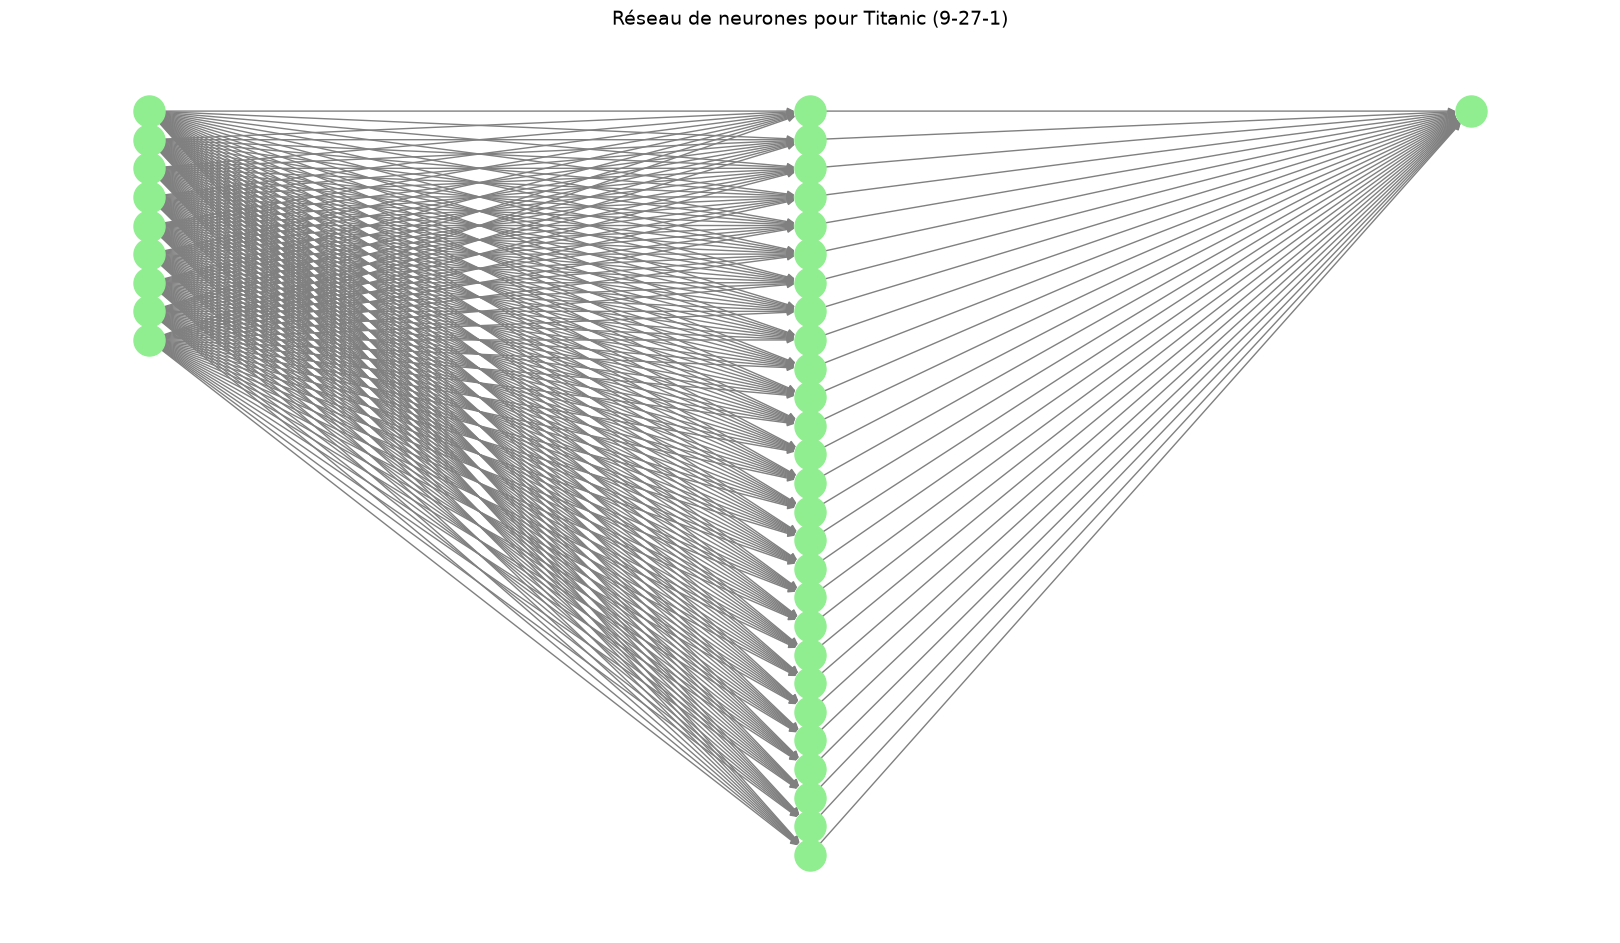

In [15]:
# 10. Visualiser la structure du réseau de neurones avec NetworkX
# On définit l'architecture sous forme de liste de couches : 
# 9 neurones en entrée (tes features), 27 dans la couche cachée, et 1 en sortie (survie)
layers = [9, 27, 1]

# Création d'un graphe orienté vide
G = nx.DiGraph()
pos = {}
layer_positions = []

# Étape A : Créer et positionner chaque neurone (nœud) par couche en colonnes
for l, n_neurons in enumerate(layers):
    layer_pos = []
    for i in range(n_neurons):
        node_id = f"L{l}N{i}"
        G.add_node(node_id, layer=l)
        pos[node_id] = (l, -i)  # Positionne les neurones en colonnes successives sur l'axe X
        layer_pos.append(node_id)
    layer_positions.append(layer_pos)

# Étape B : Créer les connexions (arêtes / edges) entre chaque neurone d'une couche et la couche suivante
for l in range(len(layers)-1):
    for src in layer_positions[l]:
        for dst in layer_positions[l+1]:
            G.add_edge(src, dst)

# Étape C : Affichage graphique avec Matplotlib
plt.figure(figsize=(16, 9))
nx.draw(
    G, pos, with_labels=False,
    node_size=500, node_color="lightgreen", edge_color="gray"
)
plt.title("Réseau de neurones pour Titanic (9-27-1)", fontsize=14)
plt.show()

In [16]:
# 9. Compiler et entraîner le modèle

# L'arrêt anticipé (EarlyStopping) interrompt l'entraînement lorsque la perte de validation ne baisse plus pendant 10 époques
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Configuration de la phase d'apprentissage (optimiseur, fonction de coût et métrique de suivi)
model.compile(
    optimizer='adam',                  # L'optimiseur adaptatif standard, robuste et efficace
    loss='binary_crossentropy',        # Fonction de perte (coût) idéale pour une classification binaire (0 ou 1)
    metrics=['accuracy']               # Suivi du pourcentage de bonnes prédictions en direct
)

# Lancement de l'entraînement (apprentissage des poids synaptiques et des biais)
history = model.fit(
    X_train, y_train, 
    epochs=50,                         # Nombre maximal de passages complets sur tout le dataset
    batch_size=32,                     # Nombre d'exemples traités en parallèle avant chaque mise à jour des poids
    validation_split=0.1,              # 10% des données du train mises de côté automatiquement pour surveiller la généralisation
    callbacks=[early_stop]             # Intégration du mécanisme d'arrêt anticipé pour contrer l'overfitting
)

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5359 - loss: 0.7170 - val_accuracy: 0.6111 - val_loss: 0.6429
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7063 - loss: 0.6605 - val_accuracy: 0.7917 - val_loss: 0.6031
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7344 - loss: 0.6223 - val_accuracy: 0.8056 - val_loss: 0.5742
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7297 - loss: 0.5947 - val_accuracy: 0.7778 - val_loss: 0.5518
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7234 - loss: 0.5736 - val_accuracy: 0.7917 - val_loss: 0.5326
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7375 - loss: 0.5568 - val_accuracy: 0.7917 - val_loss: 0.5169
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7484 - loss: 0.5427 - val_accuracy: 0.7778 - val_loss: 0.5036
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7547 - loss: 0.5306 - val_accuracy: 0.7778 - val_loss:

In [17]:
# 10. Évaluer le modèle sur le test set
# model.evaluate calcule la fonction de perte (loss) et la métrique (accuracy) sur les données de test (X_test, y_test)
loss, accuracy = model.evaluate(X_test, y_test)

# On affiche le pourcentage de réussite global (accuracy) formaté avec 2 chiffres après la virgule
print(f"Test Accuracy: {accuracy*100:.2f}%")

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8156 - loss: 0.4529 
Test Accuracy: 81.56%


In [18]:
# 11. Analyse détaillée et personnalisée des prédictions sur le jeu de test

# Étape A : Générer les prédictions du modèle sur le jeu de test
predictions = model.predict(X_test)

# On transforme les probabilités continues (entre 0 et 1) en classes binaires (0 ou 1) 
# en appliquant un seuil de décision à 0.5. .ravel() aplatit le tableau pour le rendre unidimensionnel.
y_pred = (predictions > 0.5).astype(int).ravel()

# Étape B : Reconstruire un DataFrame Pandas lisible à partir des données de test normalisées
df_test = pd.DataFrame(X_test, columns=feature_names)

# Étape C : Inverser la normalisation (StandardScaler) pour retrouver les valeurs d'origine 
# (par exemple, l'âge réel en années et le prix réel en dollars au lieu des valeurs centrées-réduites)
df_test[num] = scaler.inverse_transform(df_test[num])

# Étape D : Mise en forme esthétique et conversion des types pour un affichage propre
df_test['age'] = df_test['age'].round(0).astype(int)       # Arrondir l'âge à l'entier près
df_test['sibsp'] = df_test['sibsp'].astype(int)          # Nombre de frères, sœurs, conjoints en entier
df_test['parch'] = df_test['parch'].astype(int)          # Nombre de parents/enfants en entier
df_test['fare'] = df_test['fare'].round(2)               # Arrondir le prix du billet à 2 décimales

# Étape E : Création d'un tableau de bord comparatif (Réalité vs Prédictions)
df_test["True_Class"] = y_test                           # Le véritable destin du passager (0 = décédé, 1 = survivant)
df_test["Predicted_Class"] = y_pred                      # Ce qu'a prédit le réseau de neurones
df_test["Proba"] = predictions.ravel().round(3)          # La probabilité exacte estimée par le modèle (arrondie à 3 décimales)
df_test["correct"] = df_test["True_Class"] == df_test["Predicted_Class"] # Booléen (True si la prédiction est correcte, False sinon)

# Affichage des premières lignes pour analyser les résultats individuels
df_test.head(10)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,pclass_2,pclass_3,True_Class,Predicted_Class,Proba,correct
0,24,2,0,24.150000,1.0,0.0,1.0,0.0,1.0,0,0,0.131,True
1,44,0,1,16.100000,1.0,0.0,1.0,0.0,1.0,0,0,0.066,True
2,22,0,0,7.230000,1.0,0.0,0.0,0.0,1.0,1,0,0.230,False
3,41,2,0,14.110000,1.0,0.0,1.0,0.0,1.0,0,0,0.127,True
4,28,1,0,15.500000,0.0,1.0,0.0,0.0,1.0,1,1,0.705,True
5,36,1,0,17.400000,0.0,0.0,1.0,0.0,1.0,1,0,0.465,False
6,36,0,0,13.000000,0.0,0.0,1.0,1.0,0.0,1,1,0.825,True
7,45,0,0,26.549999,1.0,0.0,1.0,0.0,0.0,0,0,0.222,True
8,49,1,1,110.879997,1.0,0.0,0.0,0.0,0.0,0,0,0.416,True
9,34,1,0,26.000000,1.0,0.0,1.0,1.0,0.0,0,0,0.159,True


In [20]:
# 12. Analyse globale des performances sur le jeu de test

# A. Compter le nombre total de prédictions correctes (True) et erronées (False)
# df_test['correct'] contient des booléens indiquant si le modèle a vu juste pour chaque passager
print("Bilan des prédictions (Correct / Incorrect) :")
df_test['correct'].value_counts()


Bilan des prédictions (Correct / Incorrect) :


correct
True     146
False     33
Name: count, dtype: int64

In [21]:
# 12. Analyse globale des performances sur le jeu de test
# B. Afficher le rapport de classification détaillé (Scikit-Learn)
# Il résume les performances pour chaque classe (0 = non-survivant, 1 = survivant)
print("\nRapport de classification :")
print(classification_report(y_test, y_pred))


Rapport de classification :
              precision    recall  f1-score   support

           0       0.79      0.95      0.86       110
           1       0.88      0.61      0.72        69

    accuracy                           0.82       179
   macro avg       0.83      0.78      0.79       179
weighted avg       0.83      0.82      0.81       179

